# 3. Attention, Transformers and the Vision Transformer

Practice for module 3: scaled dot-product attention, why we divide by √d_k, positional encoding,
multi-head attention as one big matmul, self- vs cross-attention, causal autoregressive decoding with
sampling, LayerNorm + skip connections, and a ViT forward pass from patches to class probabilities.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

def softmax(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

## 3.1 Scaled dot-product attention

`softmax(QKᵀ/√d_k)·V`: every row of the attention matrix sums to 1, and every output row is a weighted
average (linear combination) of the value vectors.

In [2]:
def attention(Q, K, V, mask=None):
    scores = Q @ K.T / np.sqrt(K.shape[-1])
    if mask is not None:
        scores = np.where(mask, scores, -np.inf)
    A = softmax(scores)
    return A @ V, A

T, d = 5, 8
X = rng.normal(size=(T, d))
Wq, Wk, Wv = (rng.normal(0, 1 / np.sqrt(d), (d, d)) for _ in range(3))
out, A = attention(X @ Wq, X @ Wk, X @ Wv)
print("attention matrix (T x T):\n", A)
print("row sums:", A.sum(1))
print("output row 0 == Σ A[0,j]·V[j]:", np.allclose(out[0], A[0] @ (X @ Wv)))

attention matrix (T x T):
 [[0.164 0.14  0.309 0.234 0.154]
 [0.451 0.062 0.094 0.058 0.335]
 [0.248 0.172 0.175 0.196 0.209]
 [0.215 0.181 0.221 0.145 0.238]
 [0.336 0.056 0.238 0.106 0.264]]
row sums: [1. 1. 1. 1. 1.]
output row 0 == Σ A[0,j]·V[j]: True


## 3.2 Why divide by √d_k

For random vectors the dot product has variance ≈ d_k. Without scaling, large d_k makes softmax
nearly one-hot (saturated) and its gradients vanish.

In [3]:
for dk in [4, 64, 512]:
    q, k = rng.normal(size=(500, 1, dk)), rng.normal(size=(500, 10, dk))
    raw = (q @ k.transpose(0, 2, 1))[:, 0]                  # 500 trials, 10 keys each
    p_raw, p_scaled = softmax(raw), softmax(raw / np.sqrt(dk))
    print(f"d_k={dk:4d}: score std {raw.std():6.2f} | mean max prob unscaled {p_raw.max(1).mean():.3f}, scaled {p_scaled.max(1).mean():.3f}")

d_k=   4: score std   1.98 | mean max prob unscaled 0.494, scaled 0.303
d_k=  64: score std   8.12 | mean max prob unscaled 0.869, scaled 0.330
d_k= 512: score std  22.42 | mean max prob unscaled 0.956, scaled 0.319


## 3.3 Attention is order-agnostic -> positional encoding

Permuting the input rows just permutes the output rows: attention alone cannot see order.
Sinusoidal positional encodings make positions distinguishable.

permutation equivariant: True
with positional encoding still equivariant: False


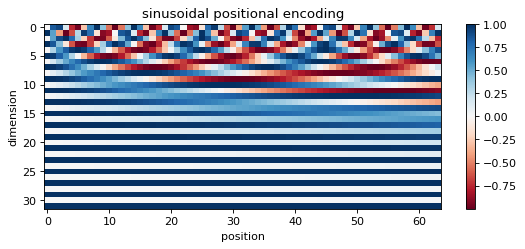

In [4]:
perm = rng.permutation(T)
out_p, _ = attention(X[perm] @ Wq, X[perm] @ Wk, X[perm] @ Wv)
print("permutation equivariant:", np.allclose(out_p, out[perm]))

def positional_encoding(n_pos, d_model):
    pos = np.arange(n_pos)[:, None]; i = np.arange(d_model // 2)[None]
    ang = pos / 10000 ** (2 * i / d_model)
    pe = np.zeros((n_pos, d_model)); pe[:, 0::2] = np.sin(ang); pe[:, 1::2] = np.cos(ang)
    return pe

PE = positional_encoding(T, d)
out_pe, _ = attention((X + PE) @ Wq, (X + PE) @ Wk, (X + PE) @ Wv)
out_pe_p, _ = attention((X[perm] + PE) @ Wq, (X[perm] + PE) @ Wk, (X[perm] + PE) @ Wv)
print("with positional encoding still equivariant:", np.allclose(out_pe_p, out_pe[perm]))

plt.figure(figsize=(8, 3))
plt.imshow(positional_encoding(64, 32).T, aspect="auto", cmap="RdBu")
plt.xlabel("position"); plt.ylabel("dimension"); plt.title("sinusoidal positional encoding"); plt.colorbar(); plt.show()

## 3.4 Multi-head attention with one big matmul

One `(d, 3d)` projection produces Q, K, V for all heads at once; heads run in parallel, outputs are
concatenated and a final linear layer `W_o` maps back to `d_model`, so layers can be stacked.

In [5]:
def multi_head(X, W_qkv, W_o, h):
    T, d = X.shape; dh = d // h
    qkv = X @ W_qkv                                          # (T, 3d) in one matmul
    q, k, v = (m.reshape(T, h, dh).transpose(1, 0, 2) for m in np.split(qkv, 3, axis=1))
    A = softmax(q @ k.transpose(0, 2, 1) / np.sqrt(dh))      # (h, T, T)
    heads = A @ v                                            # (h, T, dh)
    return heads.transpose(1, 0, 2).reshape(T, d) @ W_o, A

h = 2
W_qkv = rng.normal(0, 1 / np.sqrt(d), (d, 3 * d)); W_o = rng.normal(0, 1 / np.sqrt(d), (d, d))
mh, A_heads = multi_head(X, W_qkv, W_o, h)

# reference: loop over heads with separate small matrices
Wq_, Wk_, Wv_ = np.split(W_qkv, 3, axis=1); dh = d // h
loop = np.concatenate([attention(X @ Wq_[:, i * dh:(i + 1) * dh], X @ Wk_[:, i * dh:(i + 1) * dh],
                                 X @ Wv_[:, i * dh:(i + 1) * dh])[0] for i in range(h)], axis=1) @ W_o
print("one-matmul MHA == per-head loop:", np.allclose(mh, loop), "| output shape:", mh.shape, "== input shape", X.shape)

one-matmul MHA == per-head loop: True | output shape: (5, 8) == input shape (5, 8)


## 3.5 Self-attention vs cross-attention

In cross-attention queries come from the decoder and keys/values from the encoder output, so the
attention matrix is rectangular (decoder length × encoder length).

In [6]:
enc = rng.normal(size=(7, d))      # encoder output, 7 tokens
dec = rng.normal(size=(3, d))      # decoder states, 3 tokens
_, A_self = attention(dec @ Wq, dec @ Wk, dec @ Wv)
_, A_cross = attention(dec @ Wq, enc @ Wk, enc @ Wv)
print("self-attention matrix :", A_self.shape, "(square)")
print("cross-attention matrix:", A_cross.shape, "(rectangular)")

self-attention matrix : (3, 3) (square)
cross-attention matrix: (3, 7) (rectangular)


## 3.6 Causal decoder: generate one token at a time

A tiny decoder-only model learns the next token of the repeating sequence `0 1 2 3 4 5 0 1 ...` from
position alone. A causal mask hides future tokens. A final linear layer gives vocabulary logits, softmax
gives probabilities, and sampling picks the next token. Only the output layer is trained here
(gradient = prediction − target); attention weights stay random.

In [7]:
Vsz, dm, Tctx = 6, 16, 12
E = rng.normal(0, 1, (Vsz, dm)); PEc = positional_encoding(Tctx, dm)
Wq2, Wk2, Wv2 = (rng.normal(0, 1 / np.sqrt(dm), (dm, dm)) for _ in range(3))
W_out = np.zeros((dm, Vsz))
causal = np.tril(np.ones((Tctx, Tctx), bool))

def features(tokens):
    Xt = E[tokens] + PEc[:len(tokens)]
    a, _ = attention(Xt @ Wq2, Xt @ Wk2, Xt @ Wv2, causal[:len(tokens), :len(tokens)])
    return Xt + a                                      # skip connection

seq = np.arange(Tctx + 1) % Vsz
Hf = features(seq[:-1])
for step in range(500):
    P = softmax(Hf @ W_out)
    G = P - np.eye(Vsz)[seq[1:]]                       # softmax + CE gradient wrt logits
    W_out -= 0.1 * Hf.T @ G / Tctx
print("next-token accuracy:", (P.argmax(1) == seq[1:]).mean())

tokens = [0]
for _ in range(Tctx - 1):
    p = softmax(features(np.array(tokens))[-1] @ W_out)
    tokens.append(rng.choice(Vsz, p=p))               # sampling adds variability
print("autoregressively sampled sequence:", tokens)

# future tokens do not change earlier outputs
f1 = features(np.array([0, 1, 2, 3])); f2 = features(np.array([0, 1, 2, 5]))
print("causal mask: earlier positions unaffected by a changed future token:", np.allclose(f1[:3], f2[:3]))

next-token accuracy: 1.0
autoregressively sampled sequence: [0, 1, 2, 3, 4, 5, 0, 1, 2, 3, 4, 5]
causal mask: earlier positions unaffected by a changed future token: True


## 3.7 LayerNorm vs BatchNorm

LayerNorm normalizes each token over its features, so it works for any batch size (even 1).

In [8]:
def layer_norm(x, eps=1e-5):
    return (x - x.mean(-1, keepdims=True)) / np.sqrt(x.var(-1, keepdims=True) + eps)

B = rng.normal(3, 2, size=(4, d))
print("LayerNorm per-token mean/std:", layer_norm(B).mean(-1), layer_norm(B).std(-1))
print("a single token works too:", layer_norm(B[:1]).round(2))

LayerNorm per-token mean/std: [-0.  0.  0.  0.] [1. 1. 1. 1.]
a single token works too: [[-0.85  1.04 -0.35 -1.13 -0.77  1.   -0.61  1.68]]


## 3.8 Vision Transformer forward pass

Image -> fixed-size patches -> flatten -> linear embedding + positional encoding, prepend a class token,
run transformer blocks (pre-LN, MHA + MLP with skip connections, constant width), then a linear head on
the class token + softmax. Weights are random: the point is the pipeline and the shapes.

patches: (16, 192) -> tokens (+cls): (17, 32)
after block 1: (17, 32)
after block 2: (17, 32)
after block 3: (17, 32)
class probabilities from the class token: [0.083 0.078 0.177 0.111 0.132 0.118 0.116 0.058 0.084 0.042] sum = 1.0


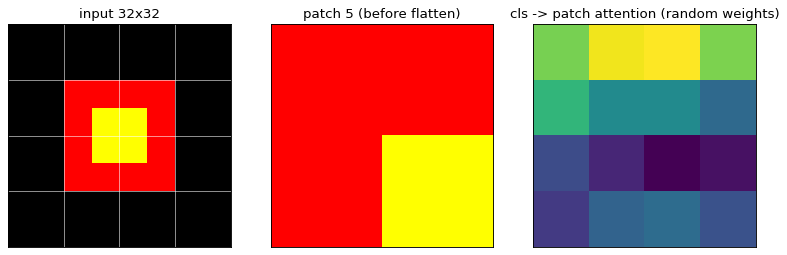

In [9]:
img = np.zeros((32, 32, 3))
img[8:24, 8:24, 0] = 1.0; img[12:20, 12:20, 1] = 1.0
P_sz, D, n_cls = 8, 32, 10

patches = img.reshape(32 // P_sz, P_sz, 32 // P_sz, P_sz, 3).transpose(0, 2, 1, 3, 4).reshape(-1, P_sz * P_sz * 3)
W_emb = rng.normal(0, 0.02, (P_sz * P_sz * 3, D))
cls = rng.normal(0, 0.02, (1, D))
tokens = np.vstack([cls, patches @ W_emb]) + positional_encoding(len(patches) + 1, D)

def block(x):
    a, A = multi_head(layer_norm(x), rng.normal(0, 1 / np.sqrt(D), (D, 3 * D)), rng.normal(0, 1 / np.sqrt(D), (D, D)), 4)
    x = x + a                                                        # skip
    m = np.maximum(0, layer_norm(x) @ rng.normal(0, 1 / np.sqrt(D), (D, 4 * D))) @ rng.normal(0, 1 / np.sqrt(4 * D), (4 * D, D))
    return x + m, A                                                  # skip; width stays D

print("patches:", patches.shape, "-> tokens (+cls):", tokens.shape)
x = tokens
for i in range(3):
    x, A_last = block(x); print(f"after block {i + 1}:", x.shape)
probs = softmax(layer_norm(x[0]) @ rng.normal(0, 0.1, (D, n_cls)))
print("class probabilities from the class token:", probs, "sum =", probs.sum().round(3))

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
axes[0].imshow(img); axes[0].set_title("input 32x32")
for k in range(1, 4): axes[0].axhline(k * P_sz - 0.5, c="w", lw=0.5); axes[0].axvline(k * P_sz - 0.5, c="w", lw=0.5)
axes[1].imshow(patches[5].reshape(P_sz, P_sz, 3)); axes[1].set_title("patch 5 (before flatten)")
axes[2].imshow(A_last.mean(0)[0, 1:].reshape(4, 4), cmap="viridis"); axes[2].set_title("cls -> patch attention (random weights)")
for a in axes: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()